# Communications

Analog and digital modulation, channels and measurements: AM, FM and SSB
with their spectra; a QPSK link measured with probes; bit error rates of
five schemes; and what interference does to a link. Modulators,
demodulators and channels are subsystems of library blocks. Every number is
checked against theory.

In [1]:
%config InlineBackend.figure_formats = ["svg"]  # crisp at any zoom
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import erfc

import sigline as sl


def Q(x):
    return 0.5 * erfc(x / np.sqrt(2))

## 1. Analog modulation

One two-tone message through AM, FM and SSB, to complex baseband, with
noise (`awgn`) and a carrier 12 kHz away (`tone_interferer`); each
demodulator filters its channel first. Compared with the message, delayed
by the channel filter (SSB also by its Hilbert filter, FM by one sample).

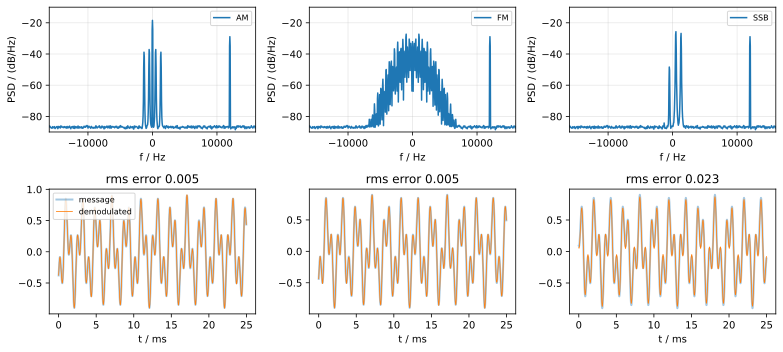

In [2]:
fs, taps = 48_000.0, 201
schemes = {
    "AM": (sl.am_mod(0.5), sl.am_demod(0.5, channel_width=6e3, taps=taps, fs=fs), 0),
    "FM": (
        sl.fm_mod(3e3, fs=fs),
        sl.fm_demod(3e3, channel_width=14e3, taps=taps, fs=fs),
        1,
    ),
    "SSB": (sl.ssb_mod(), sl.ssb_demod(channel_width=3e3, taps=taps, fs=fs), 50),
}
fig, axes = plt.subplots(2, 3, figsize=(11, 5))
for (name, (mod, demod, extra)), a1, a2 in zip(schemes.items(), *axes, strict=True):
    rx = (0.5 * sl.Sine(500.0) + 0.4 * sl.Sine(1300.0)) >> mod
    rx = rx >> sl.awgn(power=1e-4, complex=True, seed=1)
    rx = rx >> sl.tone_interferer(12e3, 0.09, complex=True)
    spec, audio = sl.SpectrumAnalyzer(nfft=1024, name=name), sl.Scope(name, keep=1200)
    rx >> spec
    rx >> demod >> audio
    sl.Diagram(audio, fs=fs).run(1.0)
    n = np.arange(int(fs) - 1200, int(fs)) - (taps - 1) // 2 - extra
    ref = 0.5 * np.cos(2 * np.pi * 500 * n / fs) + 0.4 * np.cos(
        2 * np.pi * 1300 * n / fs
    )
    spec.plot(ax=a1, max_hold=False)
    a1.set(xlim=(-16e3, 16e3), ylim=(-90, -10))
    a2.plot(1e3 * np.arange(1200) / fs, ref, lw=2, alpha=0.4, label="message")
    a2.plot(1e3 * np.arange(1200) / fs, audio.data, lw=0.8, label="demodulated")
    a2.set(
        xlabel="t / ms",
        title=f"rms error {np.sqrt(np.mean((audio.data - ref) ** 2)):.3f}",
    )
axes[1, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

AM shows its carrier and two sidebands, FM spreads wider, SSB uses one side.
Each demodulator is a subsystem; the FM one is a channel filter, a
discriminator comparing each sample with the one before, and a scale:

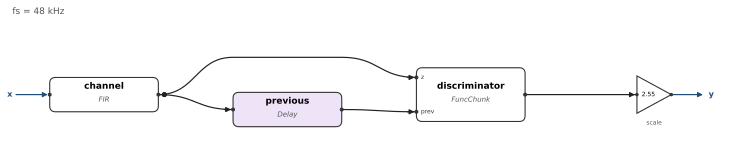

In [3]:
schemes["FM"][1].draw()
plt.show()

## 2. A QPSK link, measured

Random bits, Gray-mapped to QPSK, root-raised-cosine pulses, noise at
$E_s/N_0$ = 10 dB, matched filter, one sample per symbol, back to bits.
Measurements attach as probes, without changing the diagram. With
unit-energy pulses the decision sees $E_s/N_0$ directly, so
$\mathrm{BER} = Q(\sqrt{E_s/N_0})$ for Gray QPSK, and MER and the
decision-directed SNR equal $E_s/N_0$.

BER 6.84e-04  theory 7.83e-04  95% CI [6.05e-04, 7.70e-04]
MER 10.02 dB, SNR 10.02 dB, theory 10.00 dB


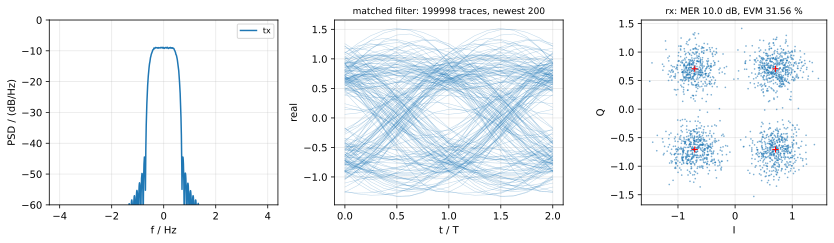

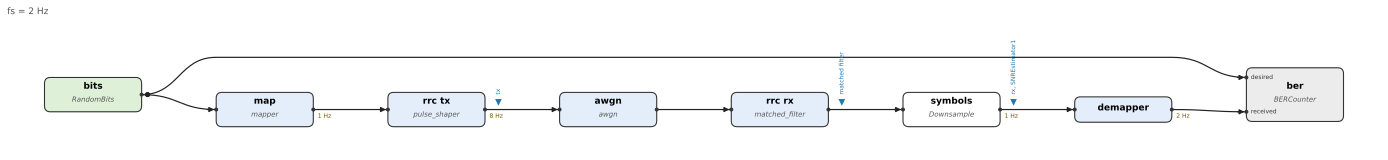

In [4]:
sps, esn0_db = 8, 10.0
QPSK = sl.psk(4)


def qpsk_link(channel, n_sym=200_000):
    # channel: parts in a row, e.g. [awgn(...), tone_interferer(...)]
    bits, ber = sl.RandomBits(seed=1, name="bits"), sl.BERCounter(sync=500, name="ber")
    rx = bits >> sl.mapper(QPSK, name="map") >> sl.pulse_shaper(sps, name="rrc tx")
    for part in channel:
        rx = rx >> part
    rx = rx >> sl.matched_filter(sps, name="rrc rx")
    rx >> sl.Downsample(sps, name="symbols") >> sl.demapper(QPSK) >> ber["received"]
    bits >> ber["desired"]
    return sl.Diagram(ber, fs=2.0), ber, 2 * n_sym


noise = 10 ** (-esn0_db / 10)
d, ber, n = qpsk_link([sl.awgn(power=noise, complex=True, seed=2, name="awgn")])
spec = d.probe("rrc tx", sink=sl.SpectrumAnalyzer(nfft=1024, name="tx"))
eye = d.probe("rrc rx", sink=sl.EyeDiagram(sps, name="matched filter"))
const = d.probe(
    "symbols", sink=sl.ConstellationScope(QPSK, keep=2000, skip=20, name="rx")
)
snr = d.probe("symbols", sink=sl.SNREstimator("dd", constellation=QPSK, skip=20))
d.run(n=n, chunk=4000)

lo, hi = ber.confidence()
theory = Q(np.sqrt(10 ** (esn0_db / 10)))
print(f"BER {ber.ber:.2e}  theory {theory:.2e}  95% CI [{lo:.2e}, {hi:.2e}]")
print(f"MER {const.mer_db:.2f} dB, SNR {snr.snr_db:.2f} dB, theory {esn0_db:.2f} dB")
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
spec.plot(ax=ax[0], max_hold=False)
ax[0].set_ylim(-60, 0)
eye.plot(ax=ax[1])
const.plot(ax=ax[2])
fig.tight_layout()
plt.show()
d

## 3. Bit error rates against theory

A sweep is a `for` loop over $E_b/N_0$. Linear schemes run at the symbol
rate (unit-energy pulses make that equivalent); BFSK through `fsk_mod` and
noncoherent `FSKDemod`. Theory, Gray coding, AWGN:
$Q(\sqrt{2E_b/N_0})$ for BPSK and QPSK,
$\approx \frac4k(1-\frac1{\sqrt M})\,Q(\sqrt{3kE_b/N_0/(M-1)})$ for square
$M$-QAM, $\frac12 e^{-E_b/2N_0}$ for noncoherent BFSK.

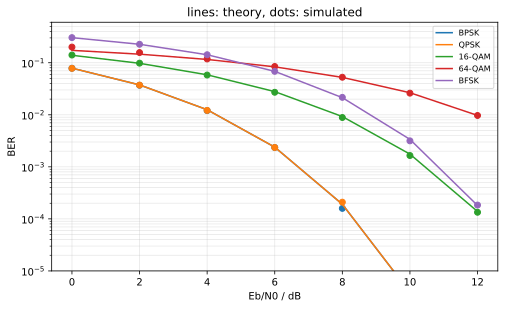

In [5]:
def ber_of(make_rx, ebn0_db, bits_per_symbol, fs, n_bits=120_000):
    bits, meter = sl.RandomBits(seed=3), sl.BERCounter(sync=600, lock_ber=0.45)
    make_rx(bits, ebn0_db) >> meter["received"]
    bits >> meter["desired"]
    k = bits_per_symbol
    sl.Diagram(meter, fs=fs).run(n=n_bits // (6 * k) * 6 * k, chunk=6000)
    return meter.ber


def linear(points):
    k = int(np.log2(len(points)))

    def rx(bits, ebn0_db):
        noise = sl.awgn(power=1 / (k * 10 ** (ebn0_db / 10)), complex=True, seed=4)
        return bits >> sl.mapper(points) >> noise >> sl.demapper(points)

    return rx, k, float(k)


def bfsk(bits, ebn0_db, sps=8):
    noise = sl.awgn(power=sps / 10 ** (ebn0_db / 10), complex=True, seed=6)
    return bits >> sl.fsk_mod(2, sps, fs=1.0) >> noise >> sl.FSKDemod(2, sps)


ebn0 = np.arange(0, 13, 2.0)
g = 10 ** (ebn0 / 10)
schemes = {
    "BPSK": (*linear(sl.psk(2)), Q(np.sqrt(2 * g))),
    "QPSK": (*linear(sl.psk(4)), Q(np.sqrt(2 * g))),
    "16-QAM": (*linear(sl.qam(16)), (1 - 1 / 4) * Q(np.sqrt(12 * g / 15))),
    "64-QAM": (*linear(sl.qam(64)), 4 / 6 * (1 - 1 / 8) * Q(np.sqrt(18 * g / 63))),
    "BFSK": (bfsk, 1, 1.0, 0.5 * np.exp(-g / 2)),
}
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, (rx, k, rate, theory) in schemes.items():
    sim = np.array([ber_of(rx, e, k, rate) for e in ebn0])
    (line,) = ax.semilogy(ebn0, theory, label=name)
    ax.semilogy(ebn0[sim > 0], sim[sim > 0], "o", color=line.get_color())
ax.set(
    xlabel="Eb/N0 / dB",
    ylabel="BER",
    ylim=(1e-5, 0.6),
    title="lines: theory, dots: simulated",
)
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=8)
plt.show()

Points below about $10^{-5}$ are missing: 120 000 bits rarely show an
error there. The QAM formula is an approximation that reads low at small
$E_b/N_0$.

## 4. Interference

The QPSK link again, with interference on top of the noise: another QPSK
transmitter, built like the wanted one, in the adjacent channel; a carrier
inside the band; bursts of impulsive noise. The matched filter removes most
of the neighbour, little of the carrier; the bursts cost bits while they
last.

noise only                           BER 6.78e-04


adjacent QPSK, +10 dB, 1.5 Rs away   BER 6.58e-04


carrier in band, -10 dB              BER 9.31e-03


impulses: 0.5 % of the time          BER 5.08e-03


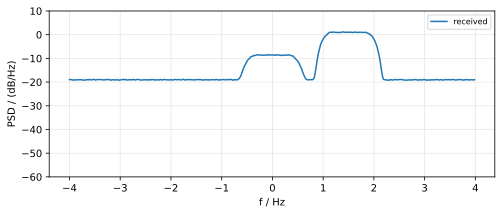

In [6]:
fs_link = 2.0 * sps / 2  # sample rate of the link: 8 samples per symbol
cases = {
    "noise only": [],
    "adjacent QPSK, +10 dB, 1.5 Rs away": [
        sl.modulated_interferer(1.5, 10.0 / sps, sps, complex=True, seed=7, fs=fs_link)
    ],
    "carrier in band, -10 dB": [sl.tone_interferer(0.1, 0.1 / sps, complex=True)],
    "impulses: 0.5 % of the time": [
        sl.impulsive_noise(5.0 / sps, p=0.0005, duration=10.0, complex=True, seed=8)
    ],
}
for name, parts in cases.items():
    d, ber, n = qpsk_link([sl.awgn(power=noise, complex=True, seed=2), *parts], 100_000)
    if "adjacent" in name:
        busy = d.probe(parts[-1], sink=sl.SpectrumAnalyzer(nfft=512, name="received"))
    d.run(n=n, chunk=4000)
    print(f"{name:36s} BER {ber.ber:.2e}")

fig, ax = plt.subplots(figsize=(8, 3))
busy.plot(ax=ax, max_hold=False)
ax.set_ylim(-60, 10)
plt.show()

## Summary

- `am_mod`/`am_demod`, `fm_mod`/`fm_demod`, `ssb_mod`/`ssb_demod`,
  `mapper`/`demapper`, `pulse_shaper`/`matched_filter`, `fsk_mod`: subsystems
  of library blocks with named inner blocks.
- Channels: `awgn`, `tone_interferer`, `modulated_interferer`,
  `impulsive_noise` and more, chained with `>>`.
- Measurements are blocks or probes: spectrum, eye, constellation, SNR,
  BER; each matches theory.